# Phase 8-R3 — KUB Baseline Infrastructure & Test-Lock Audit

This notebook verifies the CUDA-first baseline training infrastructure and governance locks for RA-MedFiLM-Seg++ (Manifest version: phase4_v2, Test lock: active).
- **KUB TRAIN**: 1,979 samples across 318 patients.
- **KUB VAL**: 283 samples across 111 patients.
- **KUB TEST**: 558 samples (LOCKED).
- **GLOBAL TEST**: 1,683 samples (LOCKED across ISIC, BUSI, Kvasir, KUB).

In [1]:
import sys, torch, json, pandas as pd, yaml, hashlib
from pathlib import Path
from IPython.display import Image, display

ROOT = Path(r'D:\Softfors\jup')
expected_python = (ROOT / '.venv' / 'Scripts' / 'python.exe').resolve()
actual_python = Path(sys.executable).resolve()
print('Expected Python:', expected_python)
print('Actual Python:  ', actual_python)
assert actual_python == expected_python, f'Wrong Jupyter kernel.\nExpected: {expected_python}\nActual:   {actual_python}'

# 1. Manifest Guard & Test Lock Live Check
from src.utils.manifest_guard import verify_manifests
from src.utils.test_lock import verify_test_lock
from src.data.kub_dataset import KUBDataset, TestAccessError

verify_manifests()
test_lock = verify_test_lock(ROOT)
assert test_lock['manifest_version'] == 'phase4_v2'
assert test_lock['test_sample_count'] == 1683
print('Manifest Guard: PASS')
print('Test Lock Verified: phase4_v2 | KUB Test Count: 558 | Global Test Count: 1683')

try:
    KUBDataset(ROOT / 'manifests' / 'test.csv', 'TEST')
except TestAccessError:
    print('Development TEST Access Blocked: PASS')
    test_blocked = True
assert test_blocked, 'Development TEST access was not blocked'

# 2. CUDA Environment
assert torch.cuda.is_available(), 'CUDA unavailable'
gpu_name = torch.cuda.get_device_name(0)
vram_bytes = torch.cuda.get_device_properties(0).total_memory
vram_gib = vram_bytes / (1024**3)
vram_gb_dec = vram_bytes / 1e9
print('\n--- CUDA ENVIRONMENT ---')
print('CUDA Available: True | GPU:', gpu_name)
print(f'Total VRAM: {vram_gib:.2f} GiB (~{vram_gb_dec:.2f} GB decimal)')
print('PyTorch Version:', torch.__version__, '| CUDA Runtime:', torch.version.cuda)

# 3. Config Display
print('\n--- CONFIG (unet_baseline.yaml) ---')
cfg_path = ROOT / 'configs' / 'kub' / 'unet_baseline.yaml'
cfg = yaml.safe_load(open(cfg_path, 'r'))
assert cfg['model']['name'] == 'unet'
assert cfg['input_resolution'] == 512
assert cfg['training']['batch_size'] == 4
assert cfg['training']['seed'] == 42
display(pd.DataFrame(list(cfg['training'].items()) + list(cfg['model'].items()), columns=['Parameter', 'Value']))

Expected Python: D:\Softfors\jup\.venv\Scripts\python.exe
Actual Python:   D:\Softfors\jup\.venv\Scripts\python.exe
Manifests verified successfully.
Manifest Guard: PASS
Test Lock Verified: phase4_v2 | KUB Test Count: 558 | Global Test Count: 1683
Development TEST Access Blocked: PASS

--- CUDA ENVIRONMENT ---
CUDA Available: True | GPU: NVIDIA GeForce RTX 3060 Ti
Total VRAM: 8.00 GiB (~8.59 GB decimal)
PyTorch Version: 2.6.0+cu124 | CUDA Runtime: 12.4

--- CONFIG (unet_baseline.yaml) ---


,Parameter,Value
0,max_epochs,100
1,early_stopping_patience,15
2,monitor,val_macro_dice
3,threshold,0.5
4,seed,42
5,amp,True
6,batch_size,4
7,gradient_accumulation_steps,1
8,effective_batch_size,4
9,num_workers,0


In [2]:
print('--- DATASET LIVE VERIFICATION ---')
from src.data.kub_dataset import KUBDataset
from src.data.transforms import SegmentationTransform
train_ds = KUBDataset(ROOT / 'manifests' / 'train.csv', 'TRAIN', SegmentationTransform(512, True), ROOT / 'reports' / 'tables' / 'kub_train_samples_sized.csv')
val_ds = KUBDataset(ROOT / 'manifests' / 'val.csv', 'VAL', SegmentationTransform(512, False), ROOT / 'reports' / 'tables' / 'kub_val_samples_sized.csv')
assert len(train_ds) == 1979, f'Expected 1979 TRAIN samples, got {len(train_ds)}'
assert len(val_ds) == 283, f'Expected 283 VAL samples, got {len(val_ds)}'
print('TRAIN dataset length:', len(train_ds), '(Verified = 1979)')
print('VAL dataset length:', len(val_ds), '(Verified = 283)')
item = train_ds[0]
assert item['image'].shape == (1, 512, 512), 'Image shape != (1, 512, 512)'
assert item['mask'].shape == (1, 512, 512), 'Mask shape != (1, 512, 512)'
unique_vals = set(torch.unique(item['mask']).tolist())
assert unique_vals.issubset({0.0, 1.0}), f'Mask values not in {{0,1}}: {unique_vals}'
print('Transformed Image shape:', item['image'].shape, 'dtype:', item['image'].dtype)
print('Transformed Mask shape:', item['mask'].shape, 'dtype:', item['mask'].dtype, 'unique values:', list(unique_vals))

--- DATASET LIVE VERIFICATION ---
TRAIN dataset length: 1979 (Verified = 1979)
VAL dataset length: 283 (Verified = 283)


Transformed Image shape: torch.Size([1, 512, 512]) dtype: torch.float32
Transformed Mask shape: torch.Size([1, 512, 512]) dtype: torch.float32 unique values: [0.0, 1.0]


In [3]:
print('--- KUB_SIZE_V1 TAXONOMY DISPLAY ---')
with open(ROOT / 'reports' / 'audits' / 'kub_object_size_thresholds.json') as f:
    sz = json.load(f)
assert sz['taxonomy_version'] == 'kub_size_v1'
assert abs(sz['Q25'] - 0.0001499766777599) < 1e-8
assert abs(sz['Q50'] - 0.00033976472454305) < 1e-8
assert abs(sz['Q75'] - 0.0008266496069636999) < 1e-8
print('Taxonomy Version:', sz['taxonomy_version'])
print('Q25:', sz['Q25'], '| Q50:', sz['Q50'], '| Q75:', sz['Q75'])
print('Note: TRAIN-derived, FULL_FIELD component-based, frozen, not recomputed by Phase 8.')

--- KUB_SIZE_V1 TAXONOMY DISPLAY ---
Taxonomy Version: kub_size_v1
Q25: 0.0001499766777599 | Q50: 0.00033976472454305 | Q75: 0.0008266496069636999
Note: TRAIN-derived, FULL_FIELD component-based, frozen, not recomputed by Phase 8.


## Preprocessing Diagnostics

--- PREPROCESSING DIAGNOSTICS ---


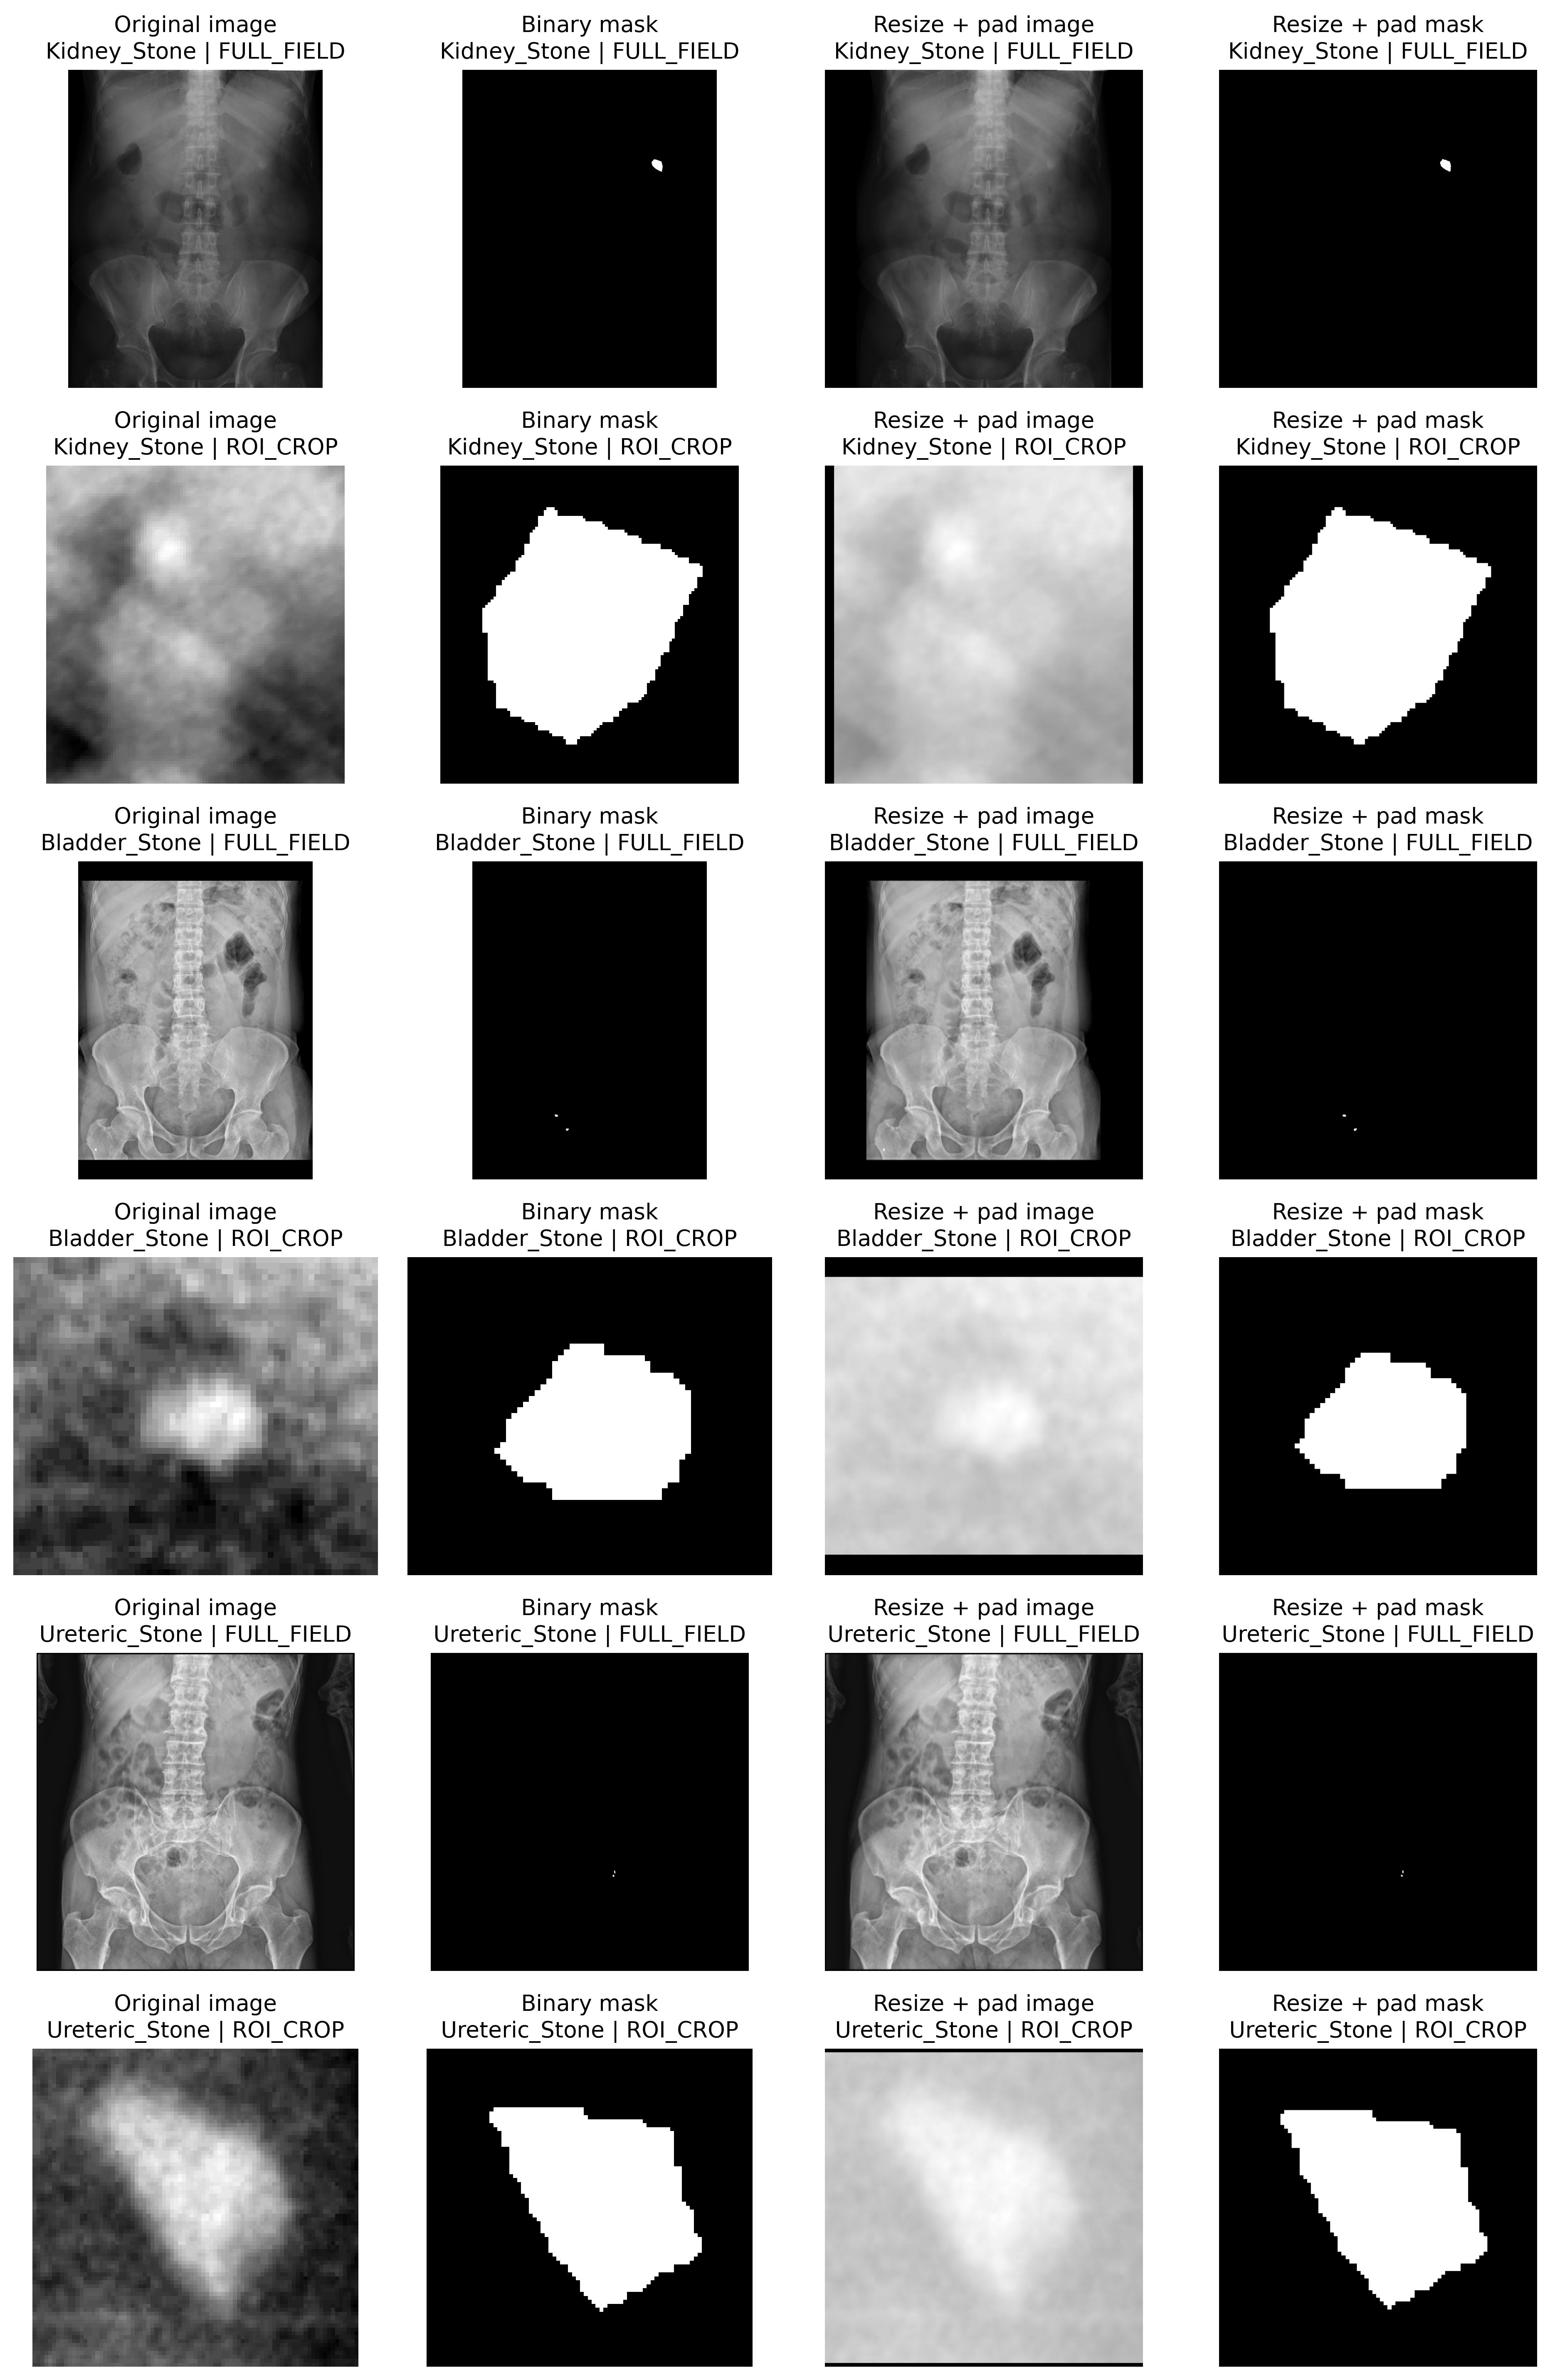

In [4]:
print('--- PREPROCESSING DIAGNOSTICS ---')
qual_img_path = ROOT / 'reports' / 'qualitative' / 'kub_baseline_infrastructure' / 'kub_preprocessing_diagnostics.png'
assert qual_img_path.exists()
display(Image(filename=str(qual_img_path)))

In [5]:
print('--- MODEL & LIVE LOSS BACKWARD SMOKE ---')
from src.models.factory import create_model
from src.losses.segmentation import BCEDiceLoss
device = torch.device('cuda')
model = create_model('unet', in_channels=1, out_channels=1, base_channels=32).to(device)
param_count = sum(p.numel() for p in model.parameters())
assert param_count == 7762465, f'Expected 7,762,465 params, got {param_count}'
print('U-Net Parameter Count:', param_count, '(Verified = 7,762,465)')
x = torch.randn(2, 1, 512, 512, device=device)
logits = model(x)
assert logits.shape == (2, 1, 512, 512)
assert torch.isfinite(logits).all()
print('Forward Input shape:', x.shape, '| Logits shape:', logits.shape, '| Finite: True')
criterion = BCEDiceLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
scaler = torch.amp.GradScaler('cuda', enabled=True)
optimizer.zero_grad(set_to_none=True)
with torch.amp.autocast('cuda', enabled=True):
    loss = criterion(logits, torch.zeros_like(logits))
assert torch.isfinite(loss)
scaler.scale(loss).backward()
scaler.step(optimizer)
scaler.update()
assert all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None)
print('Live Forward + Loss + Backward + Optimizer Step: PASS (Smoke Loss:', round(loss.item(), 4), ')')

--- MODEL & LIVE LOSS BACKWARD SMOKE ---


U-Net Parameter Count: 7762465 (Verified = 7,762,465)


Forward Input shape: torch.Size([2, 1, 512, 512]) | Logits shape: torch.Size([2, 1, 512, 512]) | Finite: True


Live Forward + Loss + Backward + Optimizer Step: PASS (Smoke Loss: 0.7515 )


In [6]:
print('--- METRIC ANALYTICAL & OBJECT TESTS ---')
import numpy as np
from src.metrics.segmentation import binary_metrics, hd95
from src.metrics.object_metrics import object_metrics
# Perfect prediction test
p_logits = torch.tensor([[[[10.]]]] * 4)
t_mask = torch.tensor([[[[1.]]]] * 4)
m = binary_metrics(p_logits, t_mask)
assert abs(m['dice'].mean().item() - 1.0) < 1e-4
assert abs(m['iou'].mean().item() - 1.0) < 1e-4
print('Case A (Perfect Prediction): Dice=1.0, IoU=1.0, Precision=1.0, Recall=1.0 (PASS)')
# Case B: No Overlap
m_none = binary_metrics(torch.tensor([[[[-10.]]]] * 4), torch.tensor([[[[1.]]]] * 4))
assert abs(m_none['dice'].mean().item() - 0.0) < 1e-4
assert abs(m_none['iou'].mean().item() - 0.0) < 1e-4
print('Case B (No Overlap): Dice=0.0, IoU=0.0, Precision=0.0, Recall=0.0 (PASS)')
# Case C: Partial Overlap
m_part = binary_metrics(torch.tensor([[[[10., -10.], [-10., -10.]]]]), torch.tensor([[[[1., 1.], [1., 0.]]]]))
print('Case C (Partial Overlap): Dice=', round(m_part['dice'].mean().item(), 4), '| IoU=', round(m_part['iou'].mean().item(), 4))
# HD95 empty prediction policy check
empty_hd = hd95(np.zeros((10,10)), np.ones((10,10)))
assert not empty_hd['hd95_valid']
assert empty_hd['empty_prediction']
assert np.isnan(empty_hd['hd95'])
print('HD95 Policy (Empty Prediction against Non-Empty GT): hd95_valid=False, empty_prediction=True, HD95=NaN (PASS)')
# Object metrics synthetic check
gt_obj = np.zeros((16,16)); gt_obj[2:4,2:4]=1; gt_obj[10:12,10:12]=1
pred_obj = np.zeros_like(gt_obj); pred_obj[2:4,2:4]=1; pred_obj[7,7]=1
om = object_metrics(pred_obj, gt_obj)
assert om['gt_component_count'] == 2
assert om['detected_gt_components'] == 1
print('Synthetic Object Metrics:', om)

--- METRIC ANALYTICAL & OBJECT TESTS ---
Case A (Perfect Prediction): Dice=1.0, IoU=1.0, Precision=1.0, Recall=1.0 (PASS)
Case B (No Overlap): Dice=0.0, IoU=0.0, Precision=0.0, Recall=0.0 (PASS)
Case C (Partial Overlap): Dice= 0.5 | IoU= 0.3333
HD95 Policy (Empty Prediction against Non-Empty GT): hd95_valid=False, empty_prediction=True, HD95=NaN (PASS)
Synthetic Object Metrics: {'gt_component_count': 2, 'predicted_component_count': 2, 'detected_gt_components': 1, 'missed_gt_components': 1, 'object_recall': 0.5, 'missed_object_rate': 0.5, 'false_positive_predicted_components': 1, 'connectivity': 8, 'minimum_overlap_pixels': 1}


In [7]:
print('--- LIVE CUDA SMOKE & CHECKPOINT VERIFICATION ---')
import tempfile
from src.utils.checkpointing import save_training_checkpoint, load_training_checkpoint
from src.utils.reproducibility import set_seed
set_seed(42)
chk_model = create_model('unet', in_channels=1, out_channels=1, base_channels=32).to(device).eval()
chk_opt = torch.optim.AdamW(chk_model.parameters(), lr=1e-4)
chk_sched = torch.optim.lr_scheduler.CosineAnnealingLR(chk_opt, T_max=100)
chk_scaler = torch.amp.GradScaler('cuda', enabled=True)
test_tensor = torch.randn(1, 1, 64, 64, device=device)
with torch.no_grad():
    out_before = chk_model(test_tensor).cpu()
with tempfile.TemporaryDirectory() as tmpdir:
    chk_path = Path(tmpdir) / 'smoke_checkpoint.pt'
    save_training_checkpoint(chk_path, chk_model, chk_opt, chk_sched, chk_scaler, 0, 1, 0.5, cfg, 42,
                             [{'epoch': 0}], 'phase4_v2', test_lock['full_test_sha256'], 'phase8_unet_infrastructure_smoke_seed42', 'unet', 512, 0.5)
    for p in chk_model.parameters(): p.data.zero_()
    state = load_training_checkpoint(chk_path, chk_model, chk_opt, chk_sched, chk_scaler, False, device)
    with torch.no_grad():
        out_after = chk_model(test_tensor).cpu()
    assert torch.equal(out_before, out_after), 'Restored checkpoint output tensor mismatch'
    assert state['epoch'] == 0
    assert state['manifest_version'] == 'phase4_v2'
print('Live Checkpoint Save/Load Round-Trip Output Equivalence: PASS')

# Canonical Registry Lookup
print('\n--- CANONICAL EXPERIMENT REGISTRY RECORD ---')
reg_df = pd.read_csv(ROOT / 'experiments' / 'registry.csv')
smoke_rec = reg_df[reg_df['experiment_id'] == 'phase8_unet_infrastructure_smoke_seed42']
assert len(smoke_rec) >= 1, 'Registry smoke record missing'
rec_row = smoke_rec.iloc[-1]
assert rec_row['seed'] == 42
assert rec_row['image_size'] == 512
assert rec_row['batch_size'] == 4
assert rec_row['optimizer'] == 'AdamW'
assert rec_row['status'] == 'SMOKE_TEST'
display(pd.DataFrame([rec_row.to_dict()]))

--- LIVE CUDA SMOKE & CHECKPOINT VERIFICATION ---
Live Checkpoint Save/Load Round-Trip Output Equivalence: PASS

--- CANONICAL EXPERIMENT REGISTRY RECORD ---


,experiment_id,phase,dataset,split_scope,model,architecture,seed,image_size,batch_size,effective_batch_size,...,loss,threshold,manifest_version,status,start_time,end_time,checkpoint_path,best_val_dice,git_commit,notes
0,phase8_unet_infrastructure_smoke_seed42,8,KUB,TRAIN+VAL_SMOKE_ONLY,unet,standard_unet_4_stage,42,512,4,4,...,0.5_BCE+0.5_Dice,0.5,phase4_v2,SMOKE_TEST,NaN,NaN,D:\Softfors\jup\checkpoints\phase8_unet_infras...,SMOKE_ONLY_NOT_SCIENTIFIC,NaN,"One TRAIN batch and one VAL batch; no epoch, s..."


## Infrastructure Status Diagnostic Card (SMOKE_ONLY)

--- INFRASTRUCTURE STATUS DIAGNOSTIC CARD (SMOKE_ONLY) ---


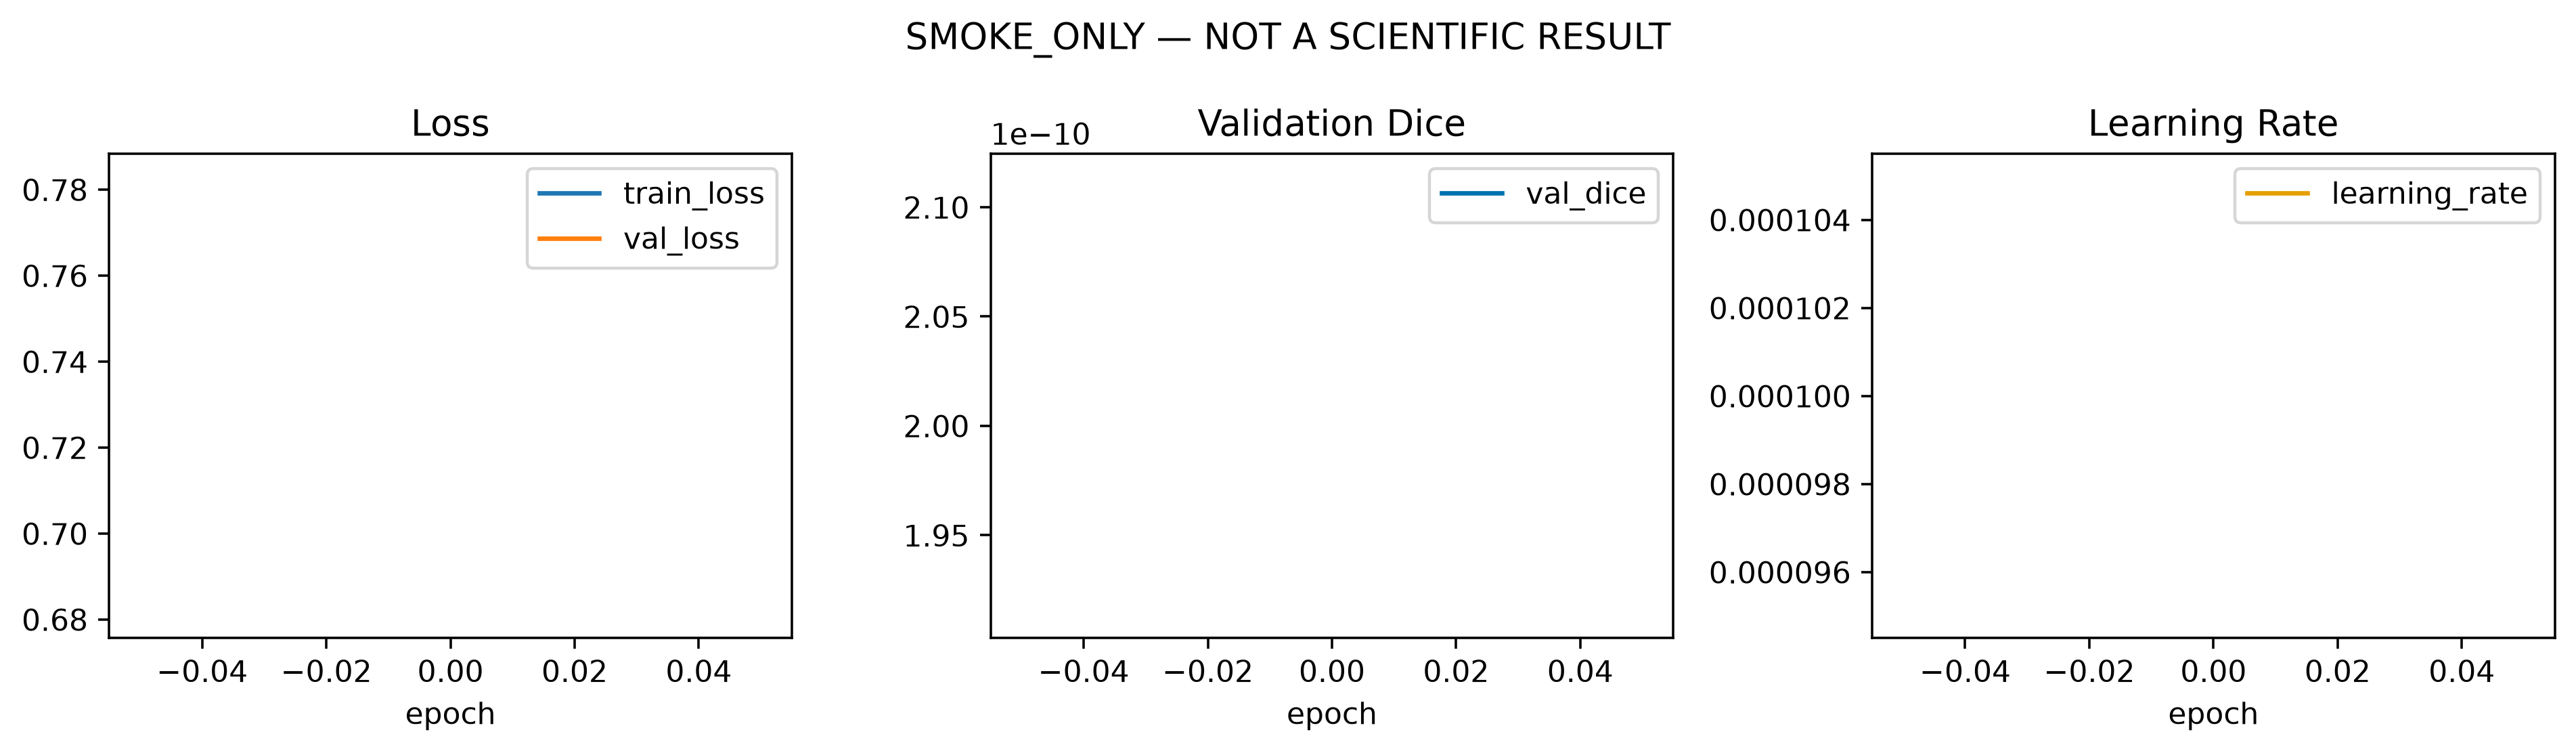

In [8]:
print('--- INFRASTRUCTURE STATUS DIAGNOSTIC CARD (SMOKE_ONLY) ---')
audit_card_path = ROOT / 'reports' / 'figures' / 'kub_baseline_infrastructure' / 'smoke_training_plumbing.png'
assert audit_card_path.exists(), 'Infrastructure status card figure missing'
display(Image(filename=str(audit_card_path)))